# Exploratory Data Analysis: Titanic Passenger Survival

**Dataset:** *Titanic Survival Data Set* — listed under **Social Sciences** in
[Awesome Public Datasets](https://github.com/awesomedata/awesome-public-datasets)
(original source: [Kaggle – Titanic](https://www.kaggle.com/c/titanic/data), `train.csv`).
The CSV in `data/titanic.csv` is an exact public mirror of that file
([datasciencedojo/datasets](https://github.com/datasciencedojo/datasets)).

**Size:** 891 rows (passengers) × 12 attributes — meets the ≥ 30 rows / ≥ 8 columns requirement.

### Approach (following the NIST/SEMATECH *e-Handbook*, Ch. 1 – Exploratory Data Analysis)
The NIST handbook describes EDA as an approach rather than a set of techniques: instead of imposing
a model on the data first (classical analysis), we **look at the data first, mostly graphically**,
and let it suggest structure, outliers and relationships. The goals it lists guide this notebook:

1. maximise insight into the data set and uncover its underlying structure,
2. extract the important variables,
3. detect outliers and anomalies,
4. test underlying assumptions,
5. develop parsimonious models / determine optimal factor settings.

NIST also stresses checking the four standard assumptions of a univariate measurement process —
**fixed location, fixed variation, randomness, and a fixed distribution** — using the **4-plot**
(run-sequence plot, lag plot, histogram, normal probability plot). Section 6 applies it.

### Outline
1. Load & inspect the data (types, missing values)
2. Univariate analysis — histograms of every numerical variable (with min, max, mean, median, outliers)
3. Univariate analysis — bar charts of every categorical variable
4. All numerical variables side by side in a single box plot
5. Bivariate analysis
   - 5a. Numerical vs numerical → scatter-plot matrix
   - 5b. Categorical vs categorical → cross-tabulation / aggregation + grouped & stacked bars, heatmap
   - 5c. Categorical vs numerical → colour (hue) encodings, grouped box/violin plots
6. NIST 4-plot for `Age` and `Fare`
7. Summary of findings

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Consistent, colour-blind-checked palette used in a FIXED order throughout
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
PALETTE = [BLUE, ORANGE, AQUA, YELLOW]
SURV_PAL = {"Died": BLUE, "Survived": ORANGE}
CLASS_PAL = {"1st": BLUE, "2nd": ORANGE, "3rd": AQUA}

sns.set_theme(style="whitegrid", context="notebook", palette=PALETTE,
              rc={"axes.edgecolor": "#c9c8c2", "grid.color": "#ecebe7",
                  "axes.titleweight": "bold", "figure.dpi": 100})
pd.set_option("display.precision", 2)

## 1. Load and inspect the data

In [2]:
df = pd.read_csv("data/titanic.csv")
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.05,NaN,S


### Data dictionary

| Column | Meaning | Type |
|---|---|---|
| `PassengerId` | Row identifier, 1–891 | numerical (discrete, identifier) |
| `Survived` | 0 = died, 1 = survived | **categorical** (binary label, stored as int) |
| `Pclass` | Ticket class: 1 = Upper, 2 = Middle, 3 = Lower | **categorical** (ordinal, stored as int) |
| `Name` | Passenger name (contains a title such as Mr/Mrs/Miss) | categorical (text) |
| `Sex` | male / female | categorical |
| `Age` | Age in years (fractional for infants) | **numerical** (continuous) |
| `SibSp` | # siblings + spouses aboard | **numerical** (discrete count) |
| `Parch` | # parents + children aboard | **numerical** (discrete count) |
| `Ticket` | Ticket number | categorical (text) |
| `Fare` | Passenger fare (pre-1970 British pounds) | **numerical** (continuous) |
| `Cabin` | Cabin number (letter = deck) | categorical (text) |
| `Embarked` | Port: C = Cherbourg, Q = Queenstown, S = Southampton | categorical |

**Numerical attributes (5):** `PassengerId`, `Age`, `SibSp`, `Parch`, `Fare`.
**Categorical attributes (7):** `Survived`, `Pclass`, `Sex`, `Embarked`, `Name`, `Ticket`, `Cabin`.

Note that `Survived` and `Pclass` are stored as integers but they are **labels**, so it would be
misleading to compute a mean of them as if they were quantities — they are treated as categorical.

In [3]:
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non-null": df.notna().sum(),
    "missing": df.isna().sum(),
    "% missing": (df.isna().mean() * 100).round(1),
    "unique values": df.nunique(),
})
info

,dtype,non-null,missing,% missing,unique values
PassengerId,int64,891,0,0.0,891
Survived,int64,891,0,0.0,2
Pclass,int64,891,0,0.0,3
Name,str,891,0,0.0,891
Sex,str,891,0,0.0,2
Age,float64,714,177,19.9,88
SibSp,int64,891,0,0.0,7
Parch,int64,891,0,0.0,7
Ticket,str,891,0,0.0,681
Fare,float64,891,0,0.0,248


**Missing values:** `Cabin` is missing for 687 passengers (77 %), `Age` for 177 (19.9 %) and
`Embarked` for 2. Everything else is complete. For this EDA we do **not** impute — summary statistics
are computed on the available values, and missing `Cabin` is shown as its own category ("Unknown")
because whether a cabin was recorded is itself informative (it is mostly recorded for 1st class).

### Derived variables for the high-cardinality text columns
`Name`, `Ticket` and `Cabin` are almost unique per passenger (891, 681 and 147 distinct values), so a
bar chart of their raw values would just be 891 bars of height 1. To chart them meaningfully we
extract the structured part of each:

* `Title` ← the honorific in `Name` (Mr, Mrs, Miss, Master, …; rare ones grouped as "Rare")
* `Deck` ← the first letter of `Cabin` (A–G, T), or "Unknown"
* `TicketGroup` ← how many passengers in the data share the same `Ticket` number

In [4]:
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df.loc[~df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Title"] = "Rare"

df["Deck"] = df["Cabin"].str[0].fillna("Unknown")
df["TicketGroup"] = df.groupby("Ticket")["Ticket"].transform("size")

# Readable labels for the coded categoricals
df["Outcome"] = df["Survived"].map({0: "Died", 1: "Survived"})
df["Class"] = df["Pclass"].map({1: "1st", 2: "2nd", 3: "3rd"})
df["Port"] = df["Embarked"].map({"C": "Cherbourg", "Q": "Queenstown", "S": "Southampton"})

NUM = ["PassengerId", "Age", "SibSp", "Parch", "Fare"]
CAT = ["Survived", "Pclass", "Sex", "Embarked", "Title", "Deck", "TicketGroup"]
df[["Title", "Deck", "TicketGroup"]].head()

,Title,Deck,TicketGroup
0,Mr,Unknown,1
1,Mrs,C,1
2,Miss,Unknown,1
3,Mrs,C,2
4,Mr,Unknown,1


## 2. Univariate analysis — numerical variables

For each numerical variable we report **min, max, mean, median, standard deviation, skewness**
and **outliers**. Outliers are identified with Tukey's rule (the same rule a box plot uses): a value
is an outlier if it lies below **Q1 − 1.5·IQR** or above **Q3 + 1.5·IQR**, where IQR = Q3 − Q1.

In [5]:
def describe_numeric(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = s[(s < lo) | (s > hi)]
    return pd.Series({
        "count": len(s), "min": s.min(), "max": s.max(), "mean": s.mean(),
        "median": s.median(), "std": s.std(), "skew": s.skew(),
        "Q1": q1, "Q3": q3, "lower fence": lo, "upper fence": hi,
        "# outliers": len(out), "% outliers": 100 * len(out) / len(s),
    })

summary = pd.DataFrame({c: describe_numeric(df[c]) for c in NUM}).T
summary

,count,min,max,mean,median,std,skew,Q1,Q3,lower fence,upper fence,# outliers,% outliers
PassengerId,891.0,1.00,891.00,446.00,446.00,257.35,0.00,223.50,668.5,-444.00,1336.00,0.0,0.00
Age,714.0,0.42,80.00,29.70,28.00,14.53,0.39,20.12,38.0,-6.69,64.81,11.0,1.54
SibSp,891.0,0.00,8.00,0.52,0.00,1.10,3.70,0.00,1.0,-1.50,2.50,46.0,5.16
Parch,891.0,0.00,6.00,0.38,0.00,0.81,2.75,0.00,0.0,0.00,0.00,213.0,23.91
Fare,891.0,0.00,512.33,32.20,14.45,49.69,4.79,7.91,31.0,-26.72,65.63,116.0,13.02


In [6]:
def plot_hist(col, bins="auto", discrete=False, ax=None, log=False):
    s = df[col].dropna()
    st = describe_numeric(s)
    ax = ax or plt.subplots(figsize=(8, 3.8))[1]
    sns.histplot(s, bins=bins, discrete=discrete, color=BLUE, edgecolor="white",
                 linewidth=1, ax=ax)
    ax.axvline(st["mean"], color=ORANGE, lw=2, label=f"mean = {st['mean']:.2f}")
    ax.axvline(st["median"], color="#0b0b0b", lw=2, ls="--", label=f"median = {st['median']:.2f}")
    if st["# outliers"] > 0 and st["upper fence"] < s.max():
        ax.axvspan(st["upper fence"], s.max() + (1 if discrete else 0), color="#e34948", alpha=0.08,
                   label=f"outlier zone (> {st['upper fence']:.2f})")
    if log:
        ax.set_yscale("log")
    ax.set_title(f"Distribution of {col}  (n = {int(st['count'])})")
    ax.set_xlabel(col); ax.set_ylabel("count" + (" (log scale)" if log else ""))
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()
    print(f"min={st['min']:.2f}  max={st['max']:.2f}  mean={st['mean']:.2f}  "
          f"median={st['median']:.2f}  std={st['std']:.2f}  skew={st['skew']:.2f}  "
          f"outliers={int(st['# outliers'])}")

### 2.1 `PassengerId`

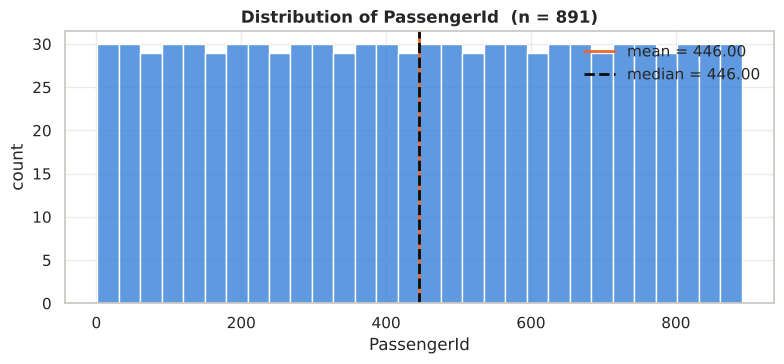

min=1.00  max=891.00  mean=446.00  median=446.00  std=257.35  skew=0.00  outliers=0


In [7]:
plot_hist("PassengerId", bins=30)

* **Min = 1, Max = 891, Mean = 446, Median = 446.**
* The histogram is perfectly flat: each ID occurs once, so the distribution is **uniform** and
  symmetric (skew = 0, mean = median).
* **Outliers: none** — the Tukey fences (−444, 1336) lie well outside the data range.
* This column is just a row index; it carries no information about passengers. It is kept in the
  analysis because it is numerical, and it serves as a useful *control*: in the scatter matrix
  (Section 5a) it should show no relationship with anything, and in the 4-plot it acts as the
  run-order axis.

### 2.2 `Age`

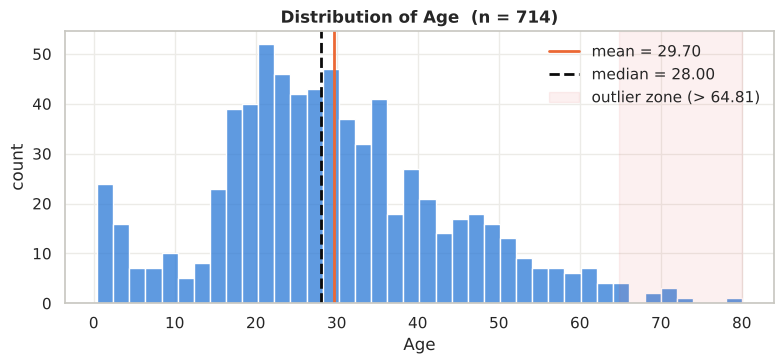

min=0.42  max=80.00  mean=29.70  median=28.00  std=14.53  skew=0.39  outliers=11


In [8]:
plot_hist("Age", bins=40)

* **Min = 0.42 years (a 5-month-old infant), Max = 80 years.**
* **Mean = 29.70, Median = 28.0** — the mean is slightly above the median, a mild **right skew**
  (skew ≈ 0.39). Most passengers were young adults aged 20–40.
* There is a visible **secondary bump at 0–5 years** (young children travelling with families).
* **Outliers: 11 passengers** above the upper fence of 64.8 years (ages 65–80). These are
  genuine elderly passengers, not data errors, so they are kept.
* **177 values (19.9 %) are missing**, which is the main data-quality issue for this variable.

### 2.3 `SibSp` (siblings / spouses aboard)

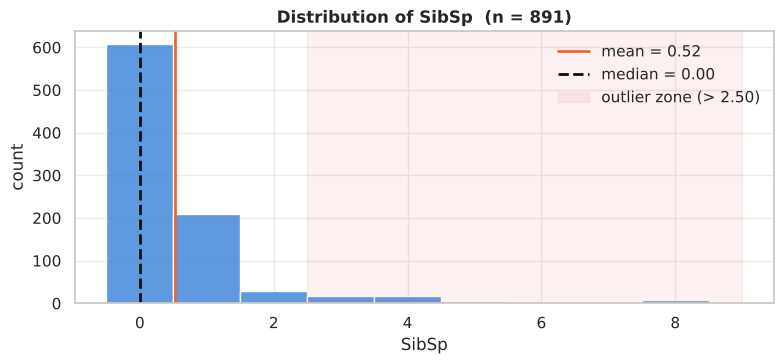

min=0.00  max=8.00  mean=0.52  median=0.00  std=1.10  skew=3.70  outliers=46


In [9]:
plot_hist("SibSp", discrete=True)

* **Min = 0, Max = 8, Mean = 0.52, Median = 0.**
* Strongly **right-skewed** (skew ≈ 3.7): 608 passengers (68 %) travelled with no sibling or
  spouse, and most of the rest had exactly one (typically a spouse).
* **Outliers: 46 passengers** with SibSp ≥ 3 (upper fence 2.5). The extreme values of 5 and 8
  belong to two large families (the Goodwin and Sage families, all 3rd class) and are real.

### 2.4 `Parch` (parents / children aboard)

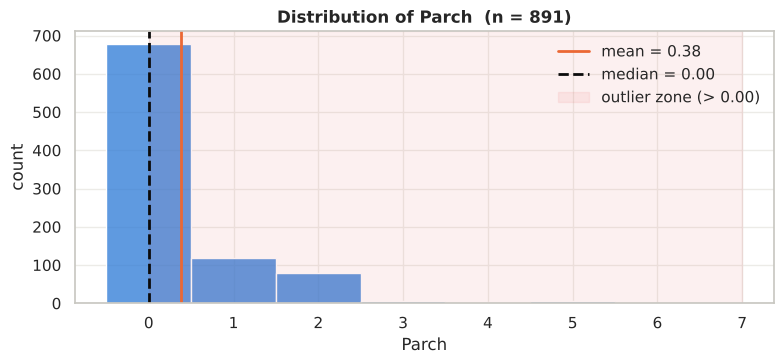

min=0.00  max=6.00  mean=0.38  median=0.00  std=0.81  skew=2.75  outliers=213


In [10]:
plot_hist("Parch", discrete=True)

* **Min = 0, Max = 6, Mean = 0.38, Median = 0.**
* Strongly **right-skewed** (skew ≈ 2.75): 678 passengers (76 %) had no parents or children aboard.
* **Outliers:** because Q1 = Q3 = 0 the IQR is 0, so Tukey's rule flags **every non-zero value
  (213 passengers)** as an outlier. This is a known weakness of the IQR rule for zero-inflated
  count data — these are not anomalies, just "travelling with family". The only values that look
  unusual in context are 4–6 (10 passengers).

### 2.5 `Fare`

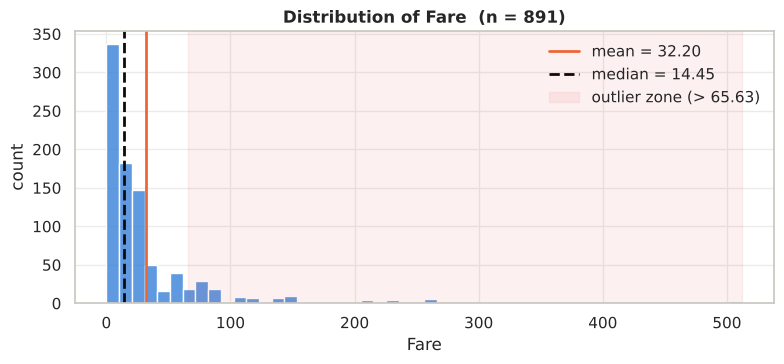

min=0.00  max=512.33  mean=32.20  median=14.45  std=49.69  skew=4.79  outliers=116


In [11]:
plot_hist("Fare", bins=50)

* **Min = 0.00, Max = 512.33, Mean = 32.20, Median = 14.45.**
* The **most skewed variable** (skew ≈ 4.8): the mean is more than double the median because
  a small number of very expensive tickets pull it upward. The median is the better "typical fare".
* **Outliers: 116 passengers** above the upper fence of 65.63 — almost all 1st-class tickets.
  The three fares of **512.33** are extreme even among these (the next highest is 263).
* **15 passengers paid a fare of 0** — likely crew/staff or complimentary tickets; this is an
  anomaly worth noting at the low end, even though the IQR rule does not flag it.
* Because of the heavy tail, a log-scale view (below) shows the structure of the bulk more clearly:
  distinct clusters of fares appear, which correspond to the three ticket classes (see Section 5c).

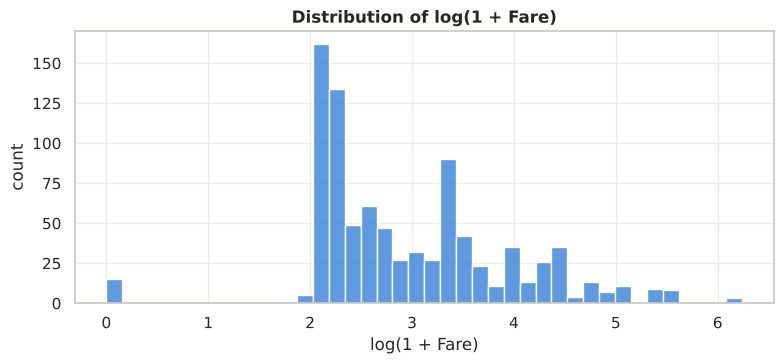

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(np.log1p(df["Fare"]), bins=40, color=BLUE, edgecolor="white", ax=ax)
ax.set_title("Distribution of log(1 + Fare)")
ax.set_xlabel("log(1 + Fare)"); ax.set_ylabel("count")
plt.tight_layout(); plt.show()

## 3. Univariate analysis — categorical variables (bar charts)

For categorical variables a histogram becomes a **bar chart of counts**. Max/min/mean/median are not
meaningful for labels, so instead we report the **mode** (most frequent category), the **least
frequent category**, and any rare categories (the categorical analogue of outliers).

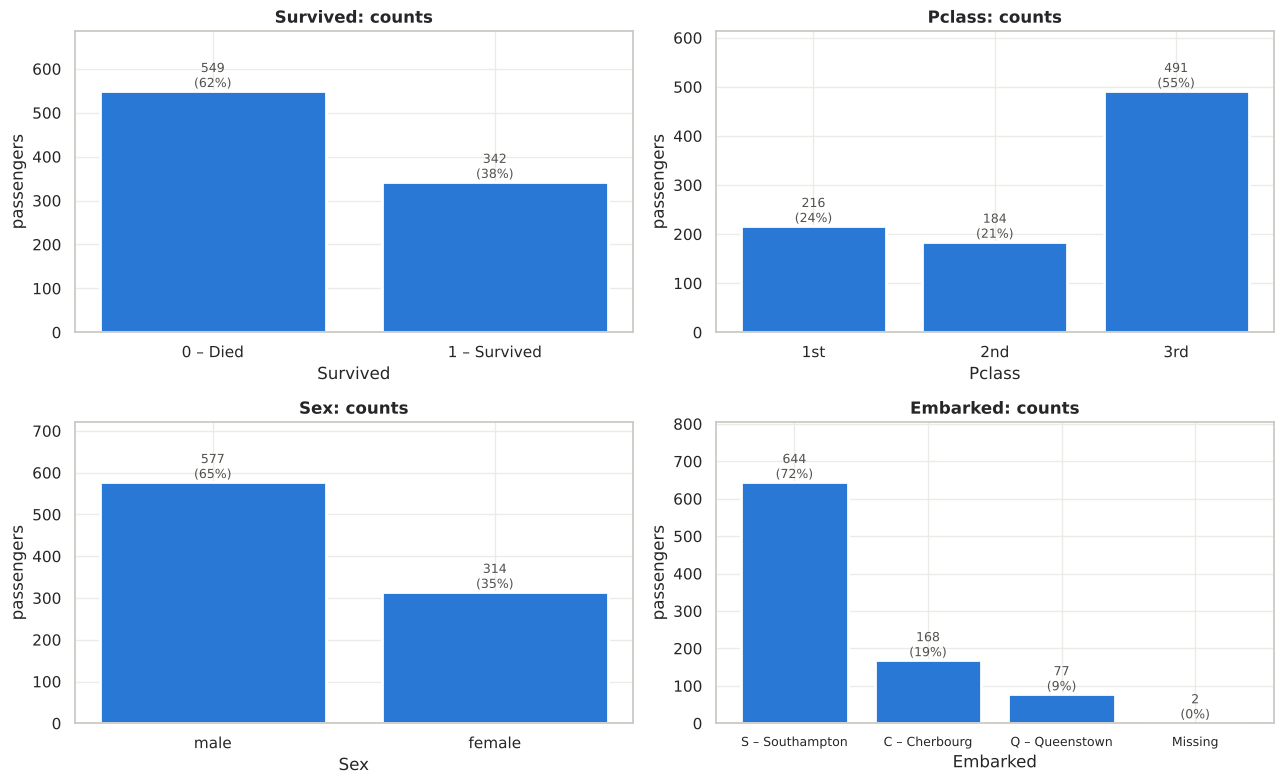

In [13]:
def plot_bar(col, order=None, labels=None, ax=None):
    counts = df[col].value_counts(dropna=False)
    if order is not None:
        counts = counts.reindex(order)
    ax = ax or plt.subplots(figsize=(6, 3.5))[1]
    x = ["Missing" if pd.isna(i) else (str(i) if labels is None else labels.get(i, str(i))) for i in counts.index]
    bars = ax.bar(x, counts.values, color=BLUE, edgecolor="white", linewidth=2)
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v}\n({100 * v / len(df):.0f}%)",
                ha="center", va="bottom", fontsize=9, color="#52514e")
    ax.set_ylim(0, counts.max() * 1.25)
    ax.set_title(f"{col}: counts"); ax.set_ylabel("passengers"); ax.set_xlabel(col)
    return ax

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
plot_bar("Survived", labels={0: "0 – Died", 1: "1 – Survived"}, ax=axes[0, 0])
plot_bar("Pclass", order=[1, 2, 3], labels={1: "1st", 2: "2nd", 3: "3rd"}, ax=axes[0, 1])
plot_bar("Sex", ax=axes[1, 0])
plot_bar("Embarked", order=["S", "C", "Q", np.nan],
         labels={"S": "S – Southampton", "C": "C – Cherbourg", "Q": "Q – Queenstown"}, ax=axes[1, 1])
axes[1, 1].tick_params(axis="x", labelsize=9)
plt.tight_layout(); plt.show()

* **`Survived`:** 549 died (61.6 %) and 342 survived (38.4 %). The classes are imbalanced but not
  extremely so. The overall survival rate of **38.4 %** is the baseline to compare every group against.
* **`Pclass`:** the mode is **3rd class with 491 passengers (55 %)**; 1st class has 216 and 2nd
  class 184 (the least frequent).
* **`Sex`:** **577 male (65 %)** vs 314 female (35 %).
* **`Embarked`:** **Southampton dominates with 644 (72 %)**, then Cherbourg 168 and Queenstown 77.
  Two passengers have no port recorded (the `nan` bar) — a rare/missing category.

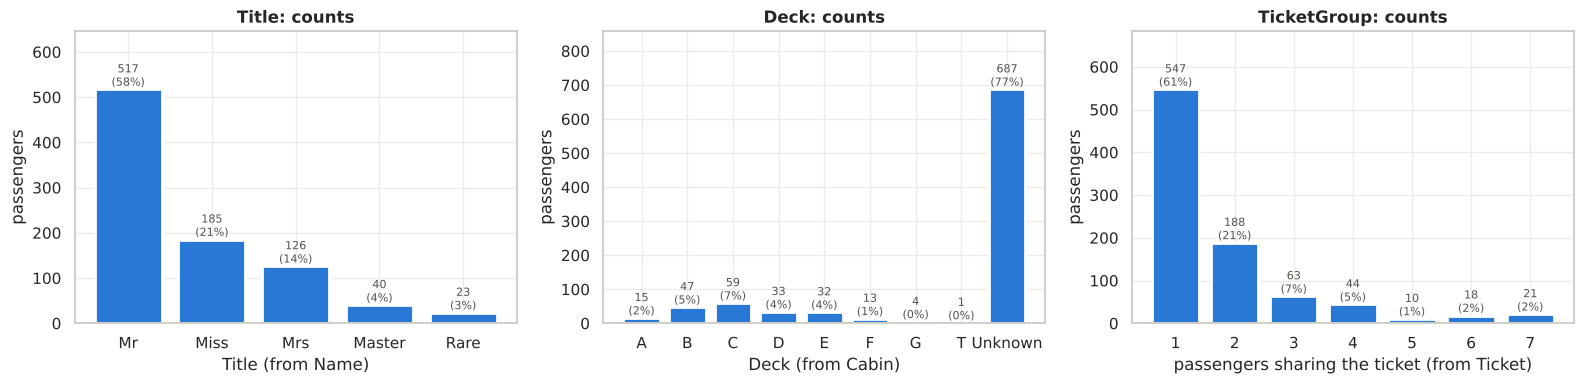

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
plot_bar("Title", order=["Mr", "Miss", "Mrs", "Master", "Rare"], ax=axes[0])
plot_bar("Deck", order=["A", "B", "C", "D", "E", "F", "G", "T", "Unknown"], ax=axes[1])
plot_bar("TicketGroup", order=sorted(df["TicketGroup"].unique()), ax=axes[2])
axes[0].set_xlabel("Title (from Name)"); axes[1].set_xlabel("Deck (from Cabin)")
axes[2].set_xlabel("passengers sharing the ticket (from Ticket)")
for ax in axes:
    for t in ax.texts:
        t.set_fontsize(8)
plt.tight_layout(); plt.show()

* **`Title` (from `Name`):** "Mr" is the mode (517, 58 %), then Miss 185, Mrs 126 and Master 40
  (boys). Only 23 passengers hold a **rare title** (Dr, Rev, Col, Major, Capt, Countess, …), grouped
  as "Rare". Title encodes sex *and* approximate age (Master = boy, Miss often = unmarried/young),
  so it is a useful compact feature.
* **`Deck` (from `Cabin`):** "Unknown" dominates (687, 77 %). Among known decks, C (59) and B (47)
  are the most common; **deck T has a single passenger** and G only 4 — rare categories.
* **`TicketGroup` (from `Ticket`):** most passengers (547) hold a ticket nobody else in the data
  shares; the rest travel on group tickets of 2–7 people. The groups of 7 are the large families
  already seen as outliers in `SibSp`/`Parch`.

## 4. All numerical variables in a single box plot

The five numerical variables are on very different scales (`SibSp` runs 0–8, `PassengerId` 1–891,
`Fare` 0–512), so putting raw values on one axis would squash most boxes flat. To compare their
**shapes side by side**, the main plot standardises each variable to a **z-score**
(z = (x − mean) / std): every box is then on the same "standard deviations from the mean" scale, and
skewness and outliers become directly comparable. The raw-unit version is shown underneath for reference.

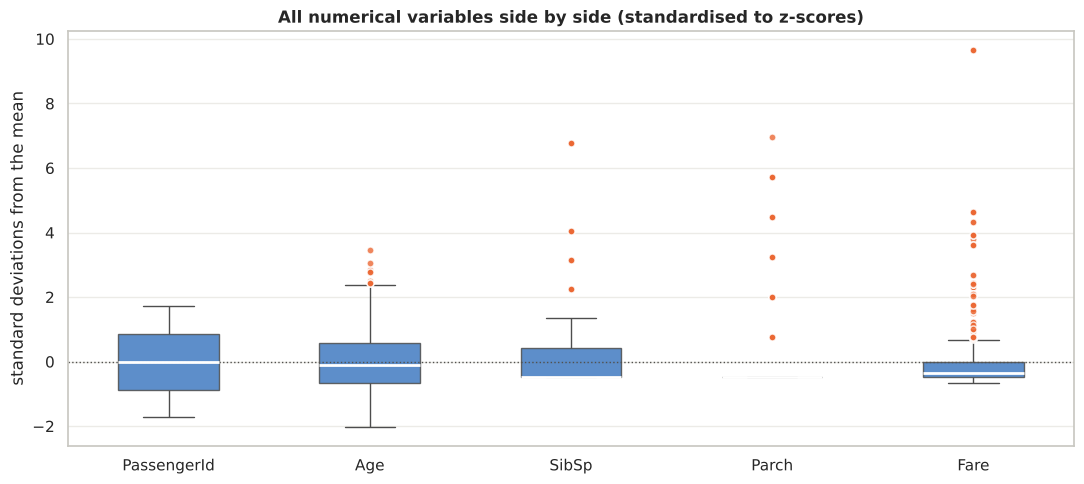

In [15]:
z = (df[NUM] - df[NUM].mean()) / df[NUM].std()
z_long = z.melt(var_name="variable", value_name="z-score").dropna()

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=z_long, x="variable", y="z-score", color=BLUE, width=0.5,
            boxprops=dict(alpha=0.85), medianprops=dict(color="white", lw=2),
            flierprops=dict(marker="o", markersize=5, markerfacecolor=ORANGE,
                            markeredgecolor="white", alpha=0.8), ax=ax)
ax.axhline(0, color="#52514e", lw=1, ls=":")
ax.set_title("All numerical variables side by side (standardised to z-scores)")
ax.set_xlabel(""); ax.set_ylabel("standard deviations from the mean")
plt.tight_layout(); plt.show()

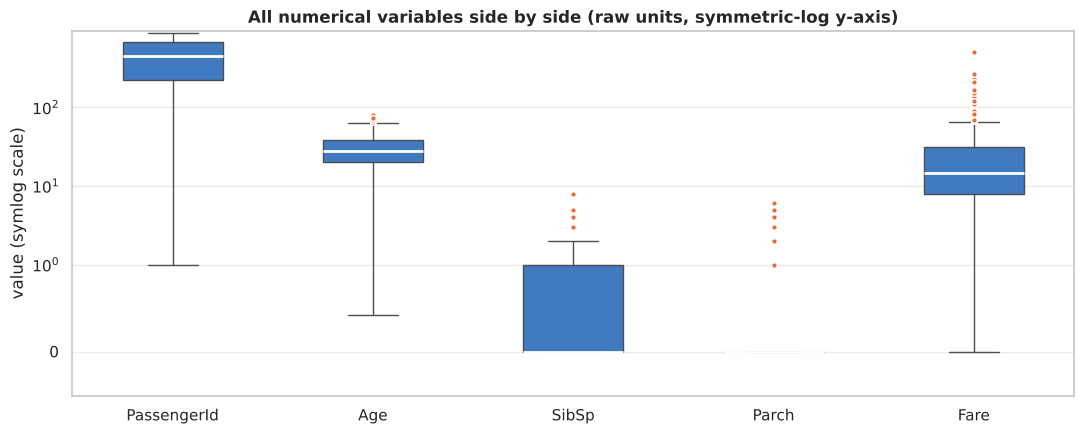

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=df[NUM].melt(var_name="variable").dropna(), x="variable", y="value",
            color=BLUE, width=0.5, medianprops=dict(color="white", lw=2),
            flierprops=dict(marker="o", markersize=4, markerfacecolor=ORANGE,
                            markeredgecolor="white"), ax=ax)
ax.set_yscale("symlog", linthresh=1); ax.set_ylim(bottom=-0.5)
ax.set_title("All numerical variables side by side (raw units, symmetric-log y-axis)")
ax.set_xlabel(""); ax.set_ylabel("value (symlog scale)")
plt.tight_layout(); plt.show()

**Reading the combined box plot:**
* `PassengerId` is the only perfectly symmetric box with no outliers (uniform).
* `Age` is close to symmetric with a short run of outliers at the top (elderly passengers).
* `SibSp`, `Parch` and `Fare` all have their median near the bottom of the box and a **long
  upper tail of outliers** — the signature of right-skewed data. `Fare` reaches **more than
  9 standard deviations** above its mean (the 512.33 tickets), the most extreme values in the data.
* `Parch` has a collapsed box (Q1 = Q3 = 0), so every non-zero value appears as an outlier, as
  discussed in 2.4.

## 5. Bivariate analysis

### 5a. Numerical vs numerical — scatter-plot matrix

A scatter-plot matrix (pair plot) shows every pair of numerical variables at once; the diagonal shows
each variable's own distribution. Points are drawn semi-transparent because `SibSp` and `Parch` are
discrete counts and many points overlap.

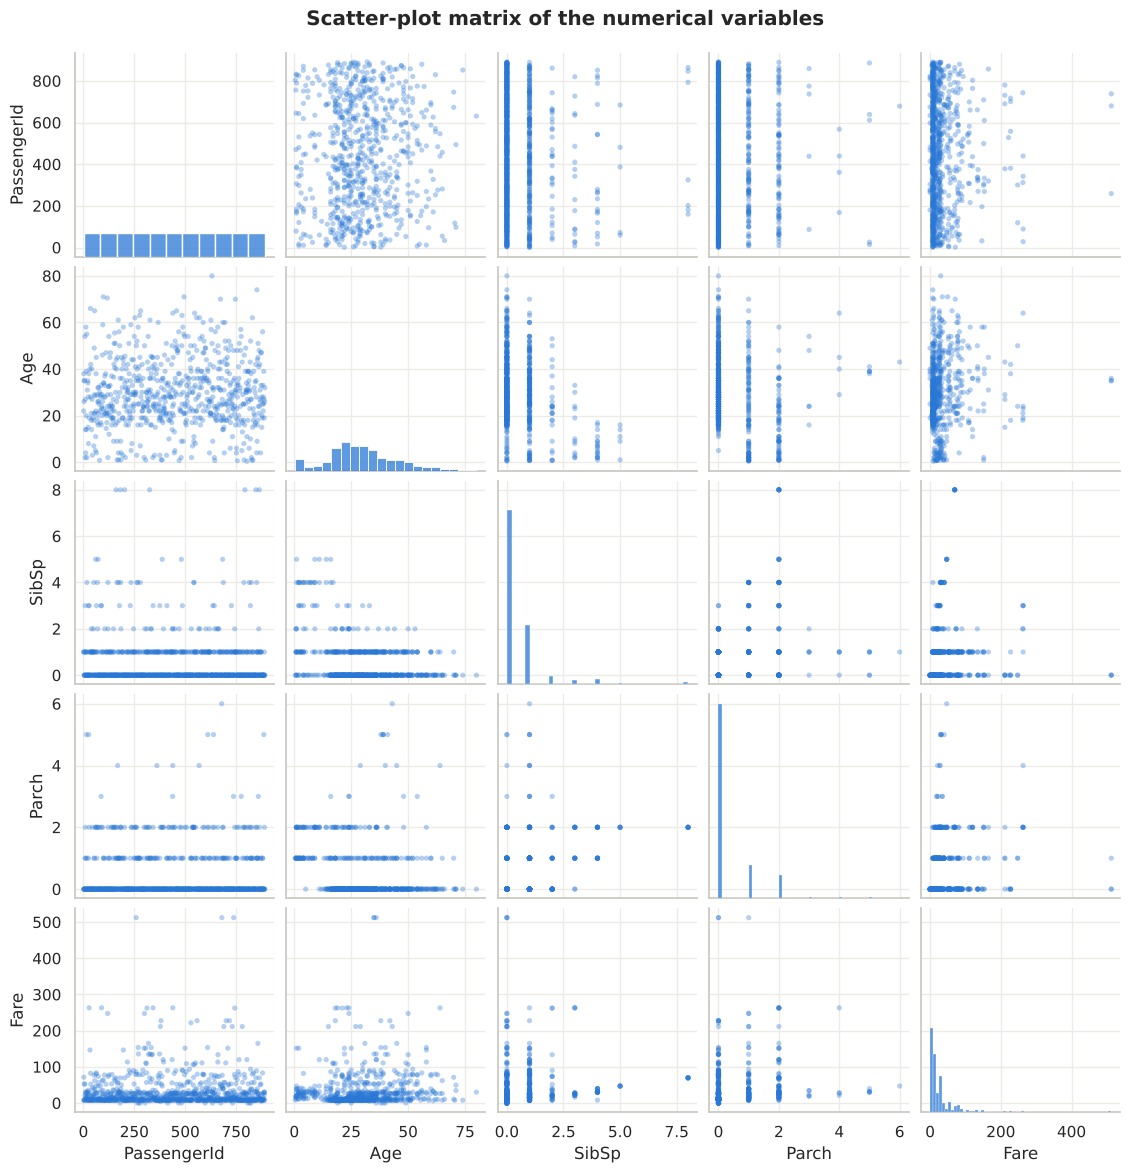

In [17]:
g = sns.pairplot(df[NUM], diag_kind="hist", corner=False, height=2.3,
                 plot_kws=dict(s=14, alpha=0.35, color=BLUE, edgecolor="none"),
                 diag_kws=dict(color=BLUE, edgecolor="white"))
g.figure.suptitle("Scatter-plot matrix of the numerical variables", y=1.02, fontweight="bold")
plt.show()

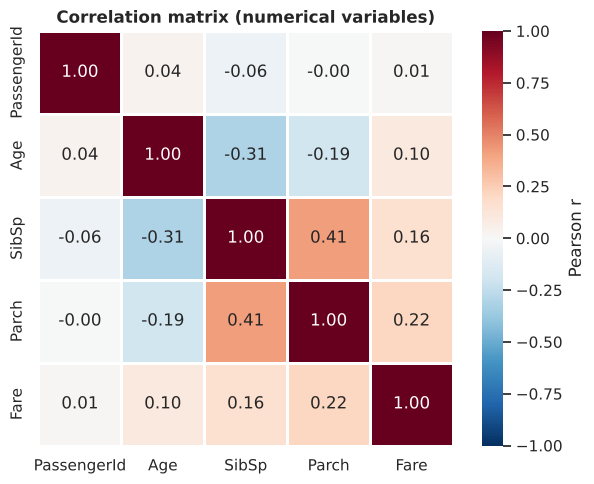

In [18]:
corr = df[NUM].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=2, linecolor="white", square=True, ax=ax,
            cbar_kws={"label": "Pearson r"})
ax.set_title("Correlation matrix (numerical variables)")
plt.tight_layout(); plt.show()

**Findings from the scatter matrix / correlations:**
* All pairwise linear correlations are **weak** (|r| ≤ 0.41) — no two numerical variables are
  redundant.
* **`SibSp` ↔ `Parch` (r = 0.41)**: the strongest relationship; both measure family size, so large
  families appear in the upper-right of that panel.
* **`Age` ↔ `SibSp` (r = −0.31)** and **`Age` ↔ `Parch` (r = −0.19)**: passengers with many
  siblings aboard are children — in the Age-vs-SibSp panel, everyone with SibSp ≥ 4 is under ~20.
* **`Fare` ↔ `Parch` / `SibSp` (r = 0.22 / 0.16)**: group tickets cost more, because the
  fare listed is for the whole ticket, not per person.
* **`PassengerId` is uncorrelated with everything** (|r| ≤ 0.06), as expected for a row index — this
  confirms there is no ordering artefact in the file.

### 5b. Categorical vs categorical — aggregate one variable against another

Scatter plots do not work for labels (points would just stack on a grid). The standard approach is to
**aggregate**: count how many observations fall in each combination of categories with a
**cross-tabulation (contingency table)**, then show it as

* a **grouped (clustered) bar chart** of counts,
* a **100 % stacked bar chart** of proportions (compares the *rate* across groups of different sizes),
* a **heatmap** of the contingency table (or of an aggregated rate for two variables at once),

and test for association with a **chi-square test of independence**.

#### Sex × Survived

In [19]:
ct = pd.crosstab(df["Sex"], df["Outcome"], margins=True)
ct

Outcome,Died,Survived,All
Sex,,,
female,81,233,314
male,468,109,577
All,549,342,891


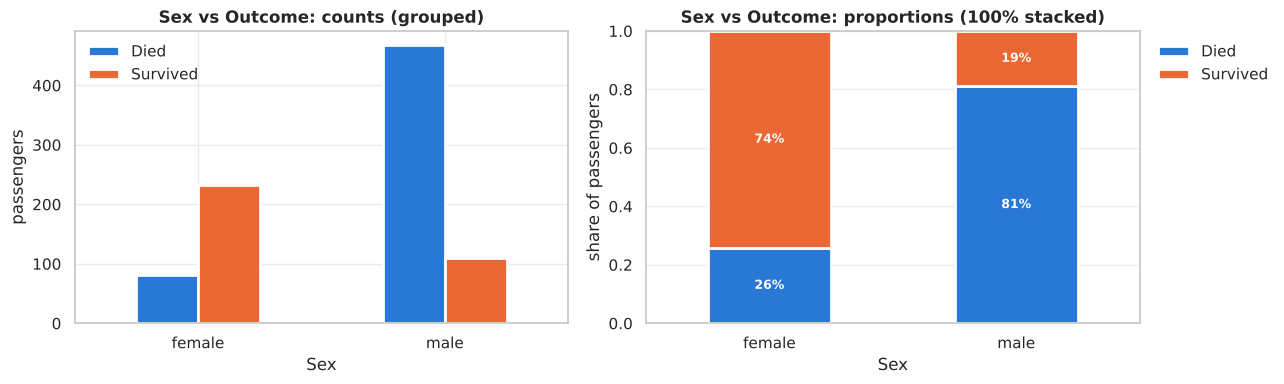

Chi-square = 260.7, dof = 1, p = 1.20e-58, Cramér's V = 0.54


In [20]:
def cat_vs_cat(row, col="Outcome", row_order=None, title=None):
    tab = pd.crosstab(df[row], df[col])
    if row_order is not None:
        tab = tab.reindex(row_order)
    prop = tab.div(tab.sum(axis=1), axis=0)
    colors = [SURV_PAL.get(c, PALETTE[i]) for i, c in enumerate(tab.columns)]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    tab.plot(kind="bar", ax=axes[0], color=colors, edgecolor="white", linewidth=2, rot=0)
    axes[0].set_title(f"{row} vs {col}: counts (grouped)"); axes[0].set_ylabel("passengers")
    prop.plot(kind="bar", stacked=True, ax=axes[1], color=colors, edgecolor="white", linewidth=2, rot=0)
    for i, (idx, r) in enumerate(prop.iterrows()):
        cum = 0
        for c in prop.columns:
            if r[c] > 0.06:
                axes[1].text(i, cum + r[c] / 2, f"{r[c]:.0%}", ha="center", va="center",
                             color="white", fontsize=9, fontweight="bold")
            cum += r[c]
    axes[1].set_title(f"{row} vs {col}: proportions (100% stacked)")
    axes[1].set_ylabel("share of passengers"); axes[1].set_ylim(0, 1)
    axes[0].legend(title="", frameon=False, loc="upper left")
    axes[1].legend(title="", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
    for ax in axes:
        ax.set_xlabel(row)
    plt.tight_layout(); plt.show()

    chi2, p, dof, _ = stats.chi2_contingency(tab)
    n = tab.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(tab.shape) - 1)))
    print(f"Chi-square = {chi2:.1f}, dof = {dof}, p = {p:.2e}, Cramér's V = {cramers_v:.2f}")

cat_vs_cat("Sex")

**74 % of women survived versus only 19 % of men** — the strongest single association in the data
(Cramér's V ≈ 0.54, p ≪ 0.001). This is the "women and children first" evacuation policy.

#### Class × Survived and Port × Survived

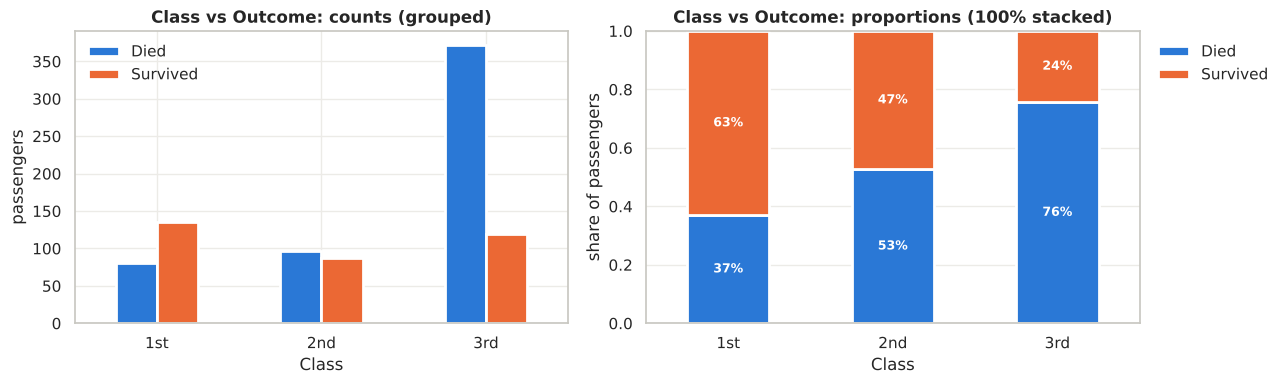

Chi-square = 102.9, dof = 2, p = 4.55e-23, Cramér's V = 0.34


In [21]:
cat_vs_cat("Class", row_order=["1st", "2nd", "3rd"])

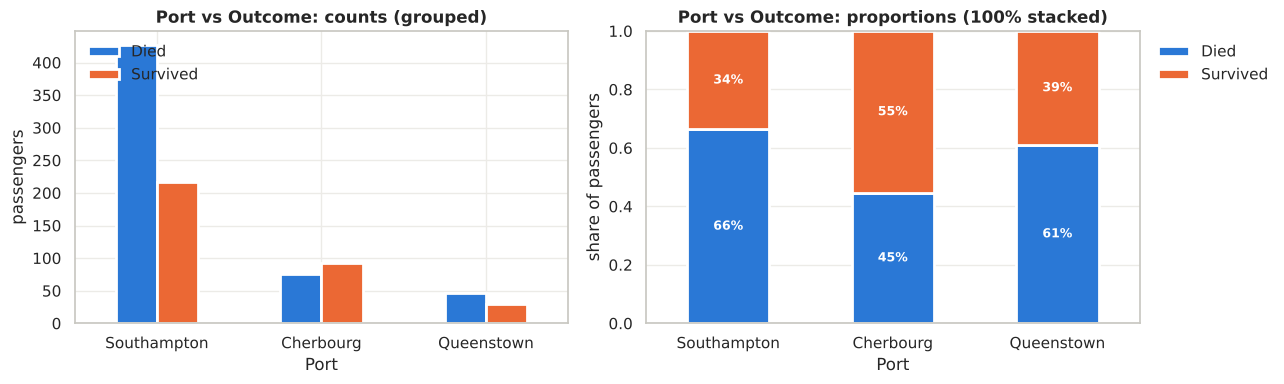

Chi-square = 26.5, dof = 2, p = 1.77e-06, Cramér's V = 0.17


In [22]:
cat_vs_cat("Port", row_order=["Southampton", "Cherbourg", "Queenstown"])

* **Class:** survival falls steadily with class — **63 % (1st) → 47 % (2nd) → 24 % (3rd)**.
  3rd class is the largest group but had by far the most deaths (372).
* **Port:** Cherbourg passengers survived more often (55 %) than Southampton (34 %). This is
  probably not a causal effect of the port itself — Cherbourg had a much higher share of
  1st-class passengers (checked in the heatmap below), i.e. a *confounder*.

#### Aggregating across two categorical variables at once
A heatmap of the **survival rate** for every Sex × Class combination aggregates `Survived` (as a mean,
i.e. a proportion) over two grouping variables simultaneously. A second heatmap shows the raw count
table for Port × Class to explain the port effect above.

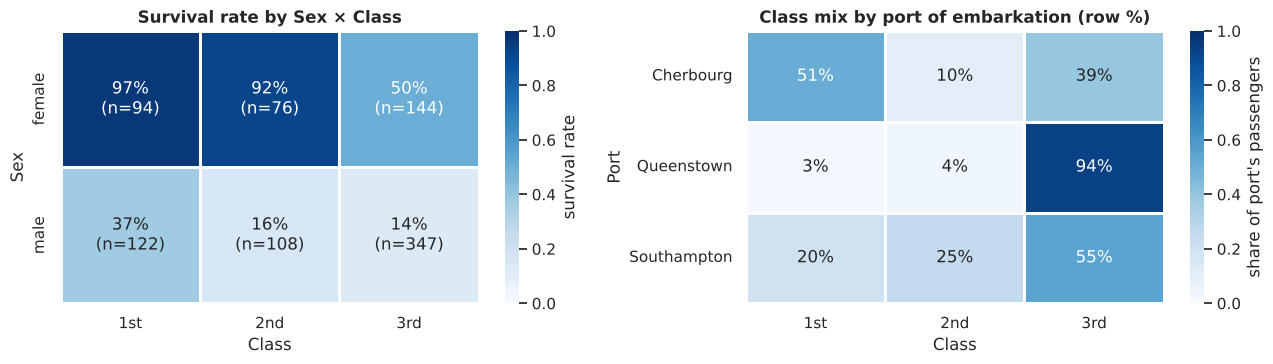

In [23]:
rate = df.pivot_table(index="Sex", columns="Class", values="Survived", aggfunc="mean")
cnt = df.pivot_table(index="Sex", columns="Class", values="Survived", aggfunc="size")
port_class = pd.crosstab(df["Port"], df["Class"], normalize="index")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
annot = rate.map(lambda v: f"{v:.0%}") + "\n(n=" + cnt.astype(str) + ")"
sns.heatmap(rate, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, linewidths=2,
            linecolor="white", cbar_kws={"label": "survival rate"}, ax=axes[0])
axes[0].set_title("Survival rate by Sex × Class")
sns.heatmap(port_class, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, linewidths=2,
            linecolor="white", cbar_kws={"label": "share of port's passengers"}, ax=axes[1])
axes[1].set_title("Class mix by port of embarkation (row %)")
plt.tight_layout(); plt.show()

* The interaction is striking: **97 % of 1st-class women and 92 % of 2nd-class women survived**,
  but only **50 % of 3rd-class women**. Among men, 1st-class men (37 %) survived at more than twice
  the rate of 2nd- and 3rd-class men (16 %, 14 %).
* **About half (51 %) of Cherbourg passengers were 1st class**, versus 20 % at Southampton and only 3 % at
  Queenstown — which accounts for most of Cherbourg's higher survival rate.

### 5c. Categorical vs numerical — use colour (hue) and grouped distributions

To relate a categorical variable to numerical ones, the category is mapped to **colour (hue)** on a
plot of the numerical data, or used to **split** the numerical distribution into side-by-side
box/violin plots or overlaid histograms. This answers "does the distribution of *x* differ between
groups?".

#### Scatter-plot matrix coloured by `Survived`
The same matrix as 5a, now with each point coloured by the categorical outcome.

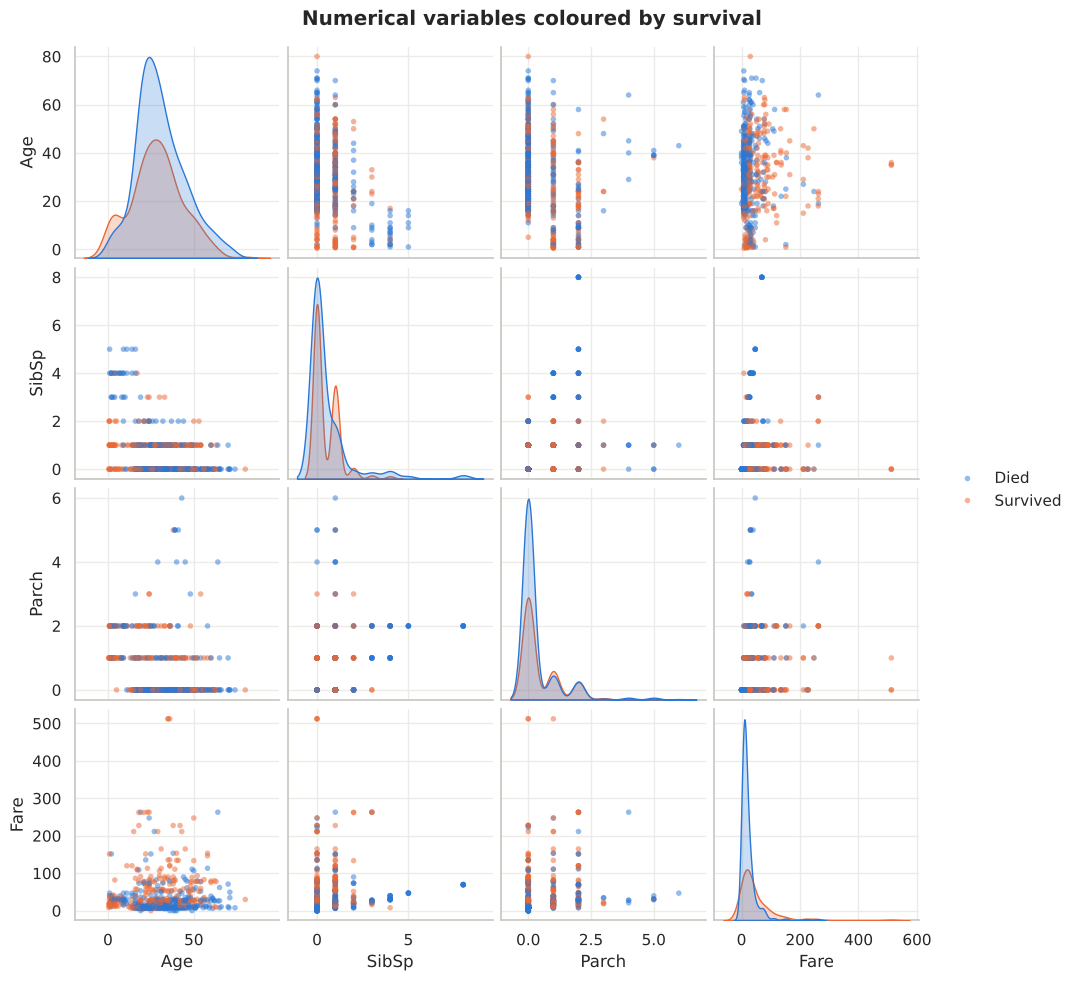

In [24]:
g = sns.pairplot(df[["Age", "SibSp", "Parch", "Fare", "Outcome"]], hue="Outcome",
                 palette=SURV_PAL, hue_order=["Died", "Survived"], height=2.4, diag_kind="kde",
                 plot_kws=dict(s=16, alpha=0.5, edgecolor="none"))
g.figure.suptitle("Numerical variables coloured by survival", y=1.02, fontweight="bold")
g._legend.set_title("")
plt.show()

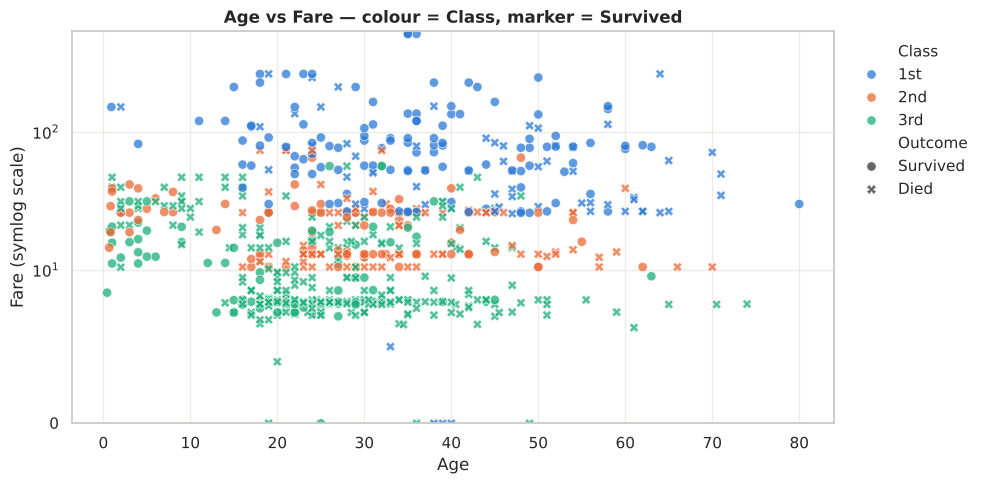

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=df, x="Age", y="Fare", hue="Class", hue_order=["1st", "2nd", "3rd"],
                style="Outcome", style_order=["Survived", "Died"], markers={"Survived": "o", "Died": "X"},
                palette=CLASS_PAL, s=45, alpha=0.75, ax=ax)
ax.set_yscale("symlog", linthresh=10); ax.set_ylim(bottom=0)
ax.set_title("Age vs Fare — colour = Class, marker = Survived")
ax.set_ylabel("Fare (symlog scale)")
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

* Colouring by class shows that **`Fare` is essentially a proxy for `Pclass`**: the three colours
  form three horizontal bands (1st class on top). This explains the clusters seen in the log-fare
  histogram in 2.5.
* Colouring by survival shows **orange (survived) dominating at high fares** and among the
  **youngest children** (left edge of the Age panels), while blue (died) dominates among low-fare,
  adult passengers.

#### Box and violin plots: numerical distributions split by category

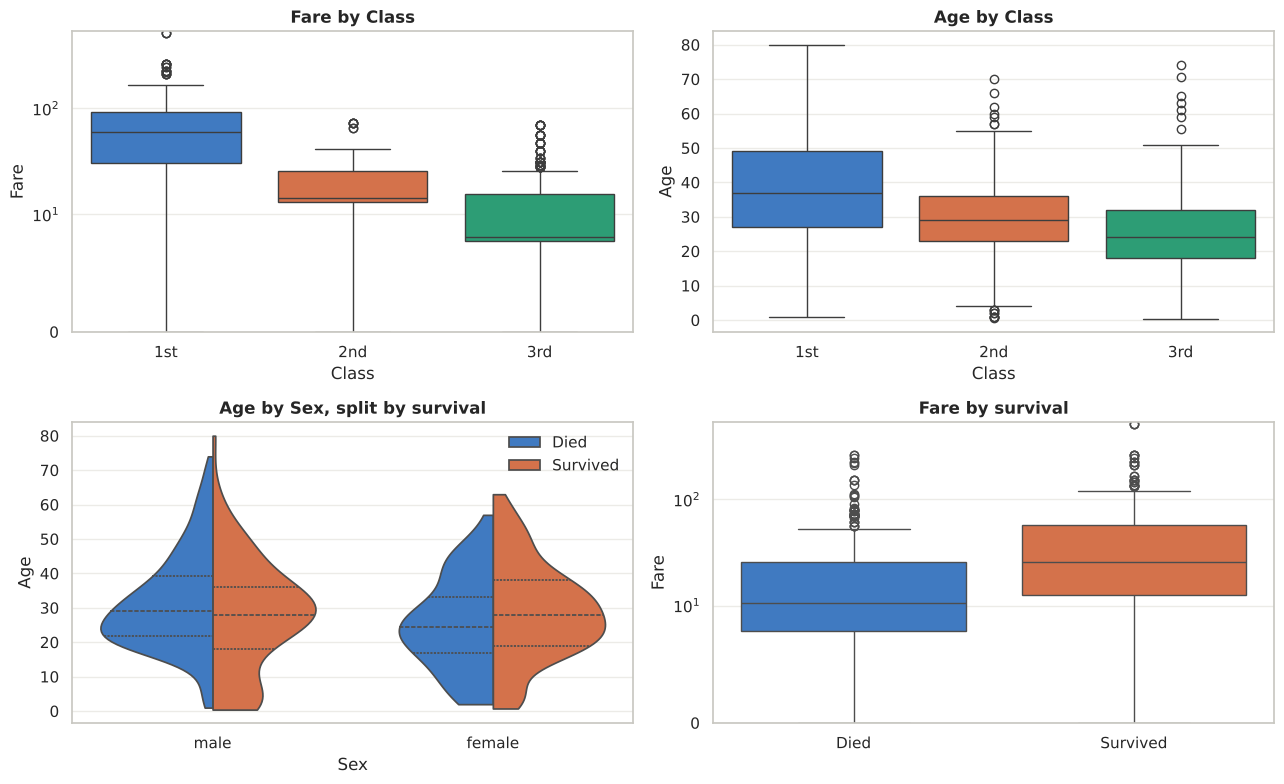

Median Fare by class: {'1st': 60.29, '2nd': 14.25, '3rd': 8.05}
Median Age by class:  {'1st': 37.0, '2nd': 29.0, '3rd': 24.0}
Median Fare by outcome: {'Died': 10.5, 'Survived': 26.0}


In [26]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.boxplot(data=df, x="Class", y="Fare", order=["1st", "2nd", "3rd"], hue="Class",
            palette=CLASS_PAL, legend=False, ax=axes[0, 0])
axes[0, 0].set_yscale("symlog", linthresh=10); axes[0, 0].set_ylim(bottom=0); axes[0, 0].set_title("Fare by Class")

sns.boxplot(data=df, x="Class", y="Age", order=["1st", "2nd", "3rd"], hue="Class",
            palette=CLASS_PAL, legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Age by Class")

sns.violinplot(data=df, x="Sex", y="Age", hue="Outcome", hue_order=["Died", "Survived"],
               palette=SURV_PAL, split=True, inner="quart", cut=0, ax=axes[1, 0])
axes[1, 0].set_title("Age by Sex, split by survival"); axes[1, 0].legend(title="", frameon=False)

sns.boxplot(data=df, x="Outcome", y="Fare", order=["Died", "Survived"], hue="Outcome",
            palette=SURV_PAL, legend=False, ax=axes[1, 1])
axes[1, 1].set_yscale("symlog", linthresh=10); axes[1, 1].set_ylim(bottom=0); axes[1, 1].set_title("Fare by survival")
axes[1, 1].set_xlabel("")
plt.tight_layout(); plt.show()

print("Median Fare by class:", df.groupby("Class")["Fare"].median().round(2).to_dict())
print("Median Age by class: ", df.groupby("Class")["Age"].median().to_dict())
print("Median Fare by outcome:", df.groupby("Outcome")["Fare"].median().round(2).to_dict())

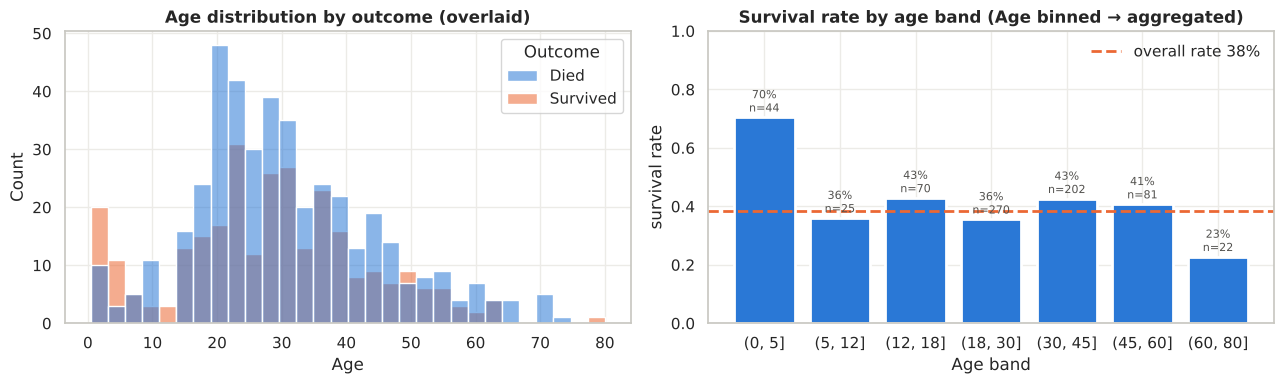

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="Age", hue="Outcome", hue_order=["Died", "Survived"], palette=SURV_PAL,
             bins=30, multiple="layer", alpha=0.55, edgecolor="white", ax=axes[0])
axes[0].set_title("Age distribution by outcome (overlaid)")

age_bins = pd.cut(df["Age"], bins=[0, 5, 12, 18, 30, 45, 60, 80])
rate_by_age = df.groupby(age_bins, observed=True)["Survived"].agg(["mean", "size"])
axes[1].bar(rate_by_age.index.astype(str), rate_by_age["mean"], color=BLUE, edgecolor="white", linewidth=2)
axes[1].axhline(df["Survived"].mean(), color=ORANGE, lw=2, ls="--", label="overall rate 38%")
for i, (m, n) in enumerate(zip(rate_by_age["mean"], rate_by_age["size"])):
    axes[1].text(i, m + 0.02, f"{m:.0%}\nn={n}", ha="center", fontsize=8, color="#52514e")
axes[1].set_ylim(0, 1); axes[1].set_title("Survival rate by age band (Age binned → aggregated)")
axes[1].set_xlabel("Age band"); axes[1].set_ylabel("survival rate"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

* **Fare by Class:** median fares of **≈ 60.3 (1st), 14.3 (2nd) and 8.05 (3rd)** — almost no overlap
  between 1st and 3rd class. Most of the `Fare` outliers from Section 2 are simply 1st-class tickets.
* **Age by Class:** 1st-class passengers were older (median 37) than 2nd (29) and 3rd (24).
* **Age × Sex × Survival (violin):** among males the survivors' distribution has a bulge at very
  young ages — boys were saved — while adult males mostly died. Among females, survivors and
  non-survivors have similar age profiles.
* **Fare by survival:** survivors paid a median of about **26** versus **10.5** for those who died.
* **Age bands:** children under 5 had the highest survival rate (≈ 70 %), well above the 38 %
  baseline; survival is near or below baseline for every adult band.

## 6. NIST 4-plot: testing the underlying assumptions

The NIST handbook's **4-plot** checks the four assumptions of a univariate process in one figure:

| Plot | Assumption checked |
|---|---|
| Run-sequence plot (value vs row order) | fixed **location** and fixed **variation** |
| Lag plot (Yᵢ vs Yᵢ₋₁) | **randomness** (no autocorrelation) |
| Histogram | shape of the **distribution** |
| Normal probability plot | whether the distribution is **normal** |

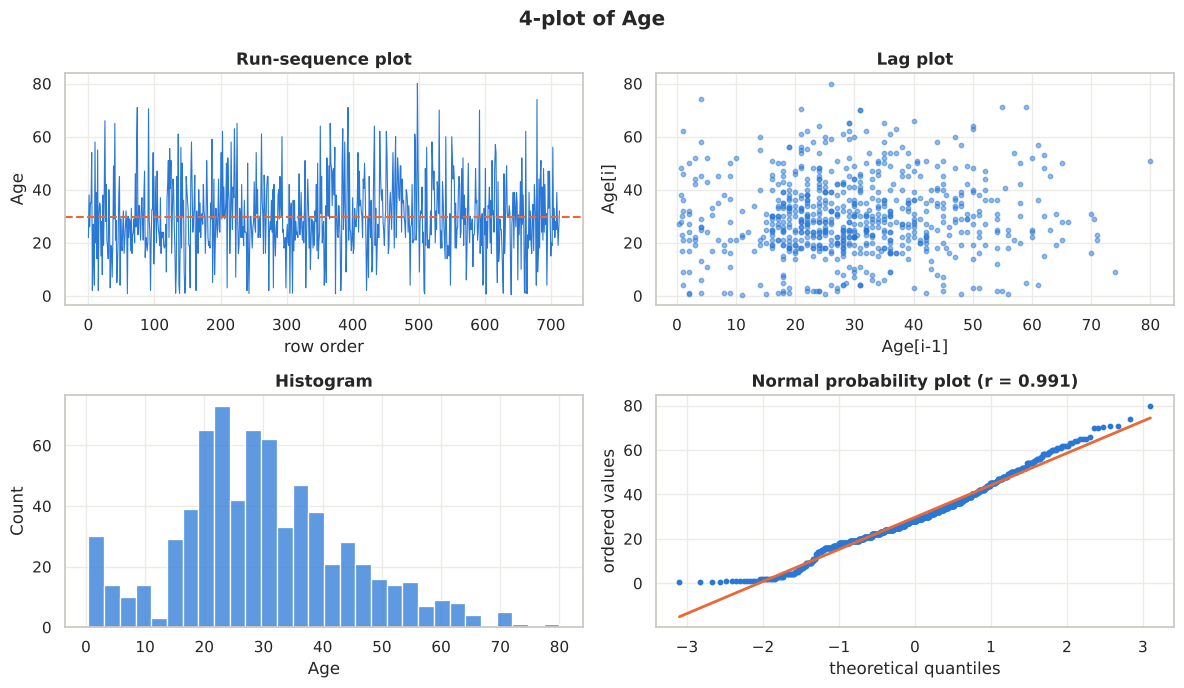

lag-1 autocorrelation = 0.049;  normal-probability-plot correlation r = 0.991


In [28]:
def four_plot(col):
    s = df[col].dropna().reset_index(drop=True)
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    axes[0, 0].plot(s.index, s.values, lw=0.8, color=BLUE)
    axes[0, 0].axhline(s.mean(), color=ORANGE, lw=1.5, ls="--")
    axes[0, 0].set_title("Run-sequence plot"); axes[0, 0].set_xlabel("row order"); axes[0, 0].set_ylabel(col)
    axes[0, 1].scatter(s.values[:-1], s.values[1:], s=10, alpha=0.5, color=BLUE)
    axes[0, 1].set_title("Lag plot"); axes[0, 1].set_xlabel(f"{col}[i-1]"); axes[0, 1].set_ylabel(f"{col}[i]")
    sns.histplot(s, bins=30, color=BLUE, edgecolor="white", ax=axes[1, 0])
    axes[1, 0].set_title("Histogram")
    (osm, osr), (slope, intercept, r) = stats.probplot(s, dist="norm")
    axes[1, 1].scatter(osm, osr, s=10, color=BLUE)
    axes[1, 1].plot(osm, slope * osm + intercept, color=ORANGE, lw=2)
    axes[1, 1].set_title(f"Normal probability plot (r = {r:.3f})")
    axes[1, 1].set_xlabel("theoretical quantiles"); axes[1, 1].set_ylabel("ordered values")
    fig.suptitle(f"4-plot of {col}", fontweight="bold")
    plt.tight_layout(); plt.show()
    lag1 = s.autocorr(lag=1)
    print(f"lag-1 autocorrelation = {lag1:.3f};  normal-probability-plot correlation r = {r:.3f}")

four_plot("Age")

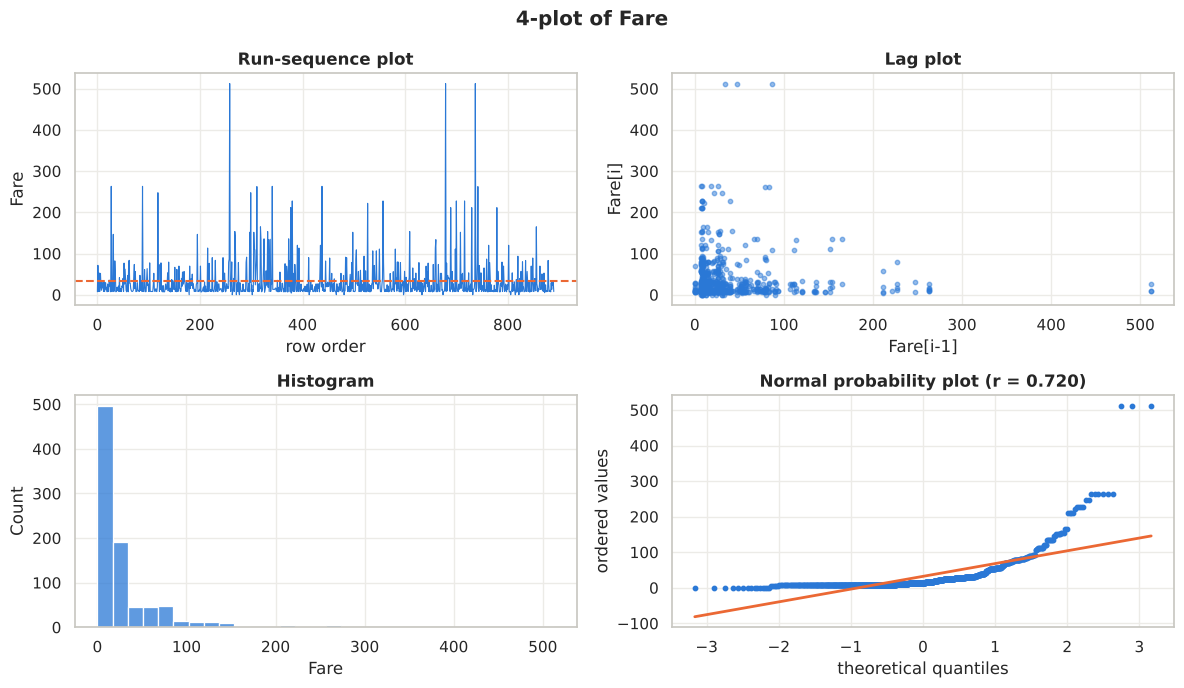

lag-1 autocorrelation = -0.011;  normal-probability-plot correlation r = 0.720


In [29]:
four_plot("Fare")

**Interpretation:**
* **Location & variation:** both run-sequence plots hover around a constant mean with constant
  spread across the file order — no drift. The rows are in a stable, arbitrary order.
* **Randomness:** both lag plots are structureless clouds and the lag-1 autocorrelations are
  essentially zero, so consecutive rows are independent.
* **Distribution:** `Age` is roughly bell-shaped — its normal probability plot is close to linear
  in the middle, bending at the tails (children and elderly), so normality is a *rough*
  approximation. `Fare` is strongly **non-normal**: the probability plot curves sharply upward,
  confirming the heavy right tail. Any method assuming normality should use a transformed fare
  (e.g. log) or a non-parametric technique.

## 7. Summary of findings

**Data quality**
* 891 passengers × 12 columns; missing data concentrated in `Cabin` (77 %) and `Age` (20 %).
* 15 zero fares and three extreme 512.33 fares are the main anomalies; age outliers (65–80) are real.

**Distributions**
* `Age` is near-symmetric (mean 29.7, median 28); `SibSp`, `Parch` and especially `Fare`
  (mean 32.2 vs median 14.5) are strongly right-skewed with long upper tails of outliers.
* The IQR outlier rule is misleading for zero-inflated counts like `Parch`.

**Relationships**
* Numerical variables are only weakly correlated; the strongest link is `SibSp`–`Parch` (family size).
* `Fare` is largely a stand-in for `Pclass`.
* Survival depends most strongly on **Sex** (74 % female vs 19 % male), then **Class**
  (63 % → 47 % → 24 %), with a strong interaction (97 % of 1st-class women vs 14 % of 3rd-class men).
* **Young children** survived at well above the baseline rate.
* The apparent port effect (Cherbourg 55 %) is mostly explained by its higher share of 1st-class passengers.

**Implication for modelling** — the variables most worth carrying forward are `Sex`/`Title`,
`Pclass` (or `Fare`, transformed), `Age` (with a strategy for missing values), and a family-size
feature built from `SibSp` + `Parch`.